# Find motifs with a top-k matrix profile

A single very close pair can win by nearest-neighbor distance. To find a
pattern with several close matches, rank each window by its mean distance
to its five nearest neighbors, then use that score in `stumpy.motifs`.
The example uses a seeded synthetic series with a close pair and six repeats
of a second pattern. To run it, install `stumpy`, `numpy`, and `matplotlib`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import stumpy

rng = np.random.default_rng(42)
m, k = 32, 5
T = rng.normal(size=640)

pair = np.repeat([0, 1, 1, -2, 0, 2, -1, 0], 4)
for start in (25, 580):
    T[start : start + m] = pair + rng.normal(scale=0.01, size=m)

wave = np.repeat([-1, 0, 2, 0, -2, -1, 2, 0], 4)
for start in (100, 182, 265, 353, 440, 520):
    T[start : start + m] = wave + rng.normal(scale=0.1, size=m)

## Rank candidates by average distance

`stumpy.stump(T, m, k=k).P_` has one row per window start and one
column per neighbor. The first column gives the nearest-neighbor distance.
Taking the mean across each row gives a one-dimensional candidate score
that `stumpy.motifs` can use. Here, `min_neighbors=k` requires five matches
within a distance of 2.0 from the representative. `max_matches=k + 1`
counts the representative itself, and `max_motifs=1` returns up to one group.

Each returned row contains one group of zero-based start indices, with the
representative first. The example sorts that row for display in time order.

In [2]:
profile = stumpy.stump(T, m, k=k)
mean_distance = profile.P_.mean(axis=1)
_, motif_indices = stumpy.motifs(
    T, mean_distance, min_neighbors=k, max_matches=k + 1, max_distance=2.0, max_motifs=1
)

pair_start = np.argmin(profile.P_[:, 0])
pair_starts = sorted([int(pair_start), int(profile.I_[pair_start, 0])])
motif_starts = sorted(motif_indices[0].tolist())
print(f"Closest pair starts at {pair_starts}")
print(f"Motif group starts at {motif_starts}")

Closest pair starts at [25, 580]
Motif group starts at [100, 182, 265, 353, 440, 520]


The two near-identical windows at 25 and 580 form the closest pair. Each
of the six windows in the blue group has five close neighbors and a lower
mean-distance score than either window in the orange pair.

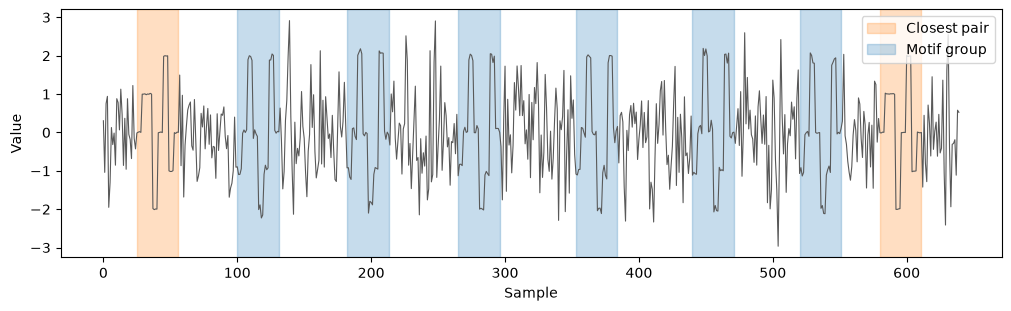

In [3]:
fig, ax = plt.subplots(figsize=(10, 3), layout="constrained")
ax.plot(T, color="0.35", linewidth=0.8)
for starts, color, label in (
    (pair_starts, "tab:orange", "Closest pair"),
    (motif_starts, "tab:blue", "Motif group"),
):
    for i, start in enumerate(starts):
        ax.axvspan(
            start, start + m - 1, color=color, alpha=0.25, label=label if i == 0 else ""
        )
ax.set(xlabel="Sample", ylabel="Value")
ax.legend(loc="upper right")
plt.show()

The neighbors in a top-k profile can be close to one another in time.
`stumpy.motifs` applies an exclusion zone when collecting the reported
matches. The mean-distance score still uses the neighbors originally
returned by `stumpy.stump`.

On your own data, choose `m` for the expected pattern length. If you get
fewer groups than requested, check `cutoff`, which limits the mean score
of a candidate, and `max_distance`, which limits individual match distances.

[STUMPY discussion on top-k motifs](https://github.com/stumpy-dev/stumpy/discussions/770#discussioncomment-6448605) · [API reference for `stumpy.motifs`](https://stumpy.readthedocs.io/en/latest/api.html#stumpy.motifs)